In [1]:

# InfraScan — Dataset Preparation
# Step 1: Set up the environment

import os
import sys
import platform

print("InfraScan Dataset Preparation")
print("-" * 40)
print("Python version:", sys.version.split()[0])
print("Platform:", platform.platform())

# Create project directories
PROJECT_DIR = "/content/InfraScan"

directories = [
    "datasets",
    "datasets/raw",
    "datasets/processed",
    "outputs",
    "outputs/eda"
]

for directory in directories:
    path = os.path.join(PROJECT_DIR, directory)
    os.makedirs(path, exist_ok=True)
    print("Created/verified:", path)

print("\nStep 1 completed successfully!")


InfraScan Dataset Preparation
----------------------------------------
Python version: 3.13.16
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
Created/verified: /content/InfraScan/datasets
Created/verified: /content/InfraScan/datasets/raw
Created/verified: /content/InfraScan/datasets/processed
Created/verified: /content/InfraScan/outputs
Created/verified: /content/InfraScan/outputs/eda

Step 1 completed successfully!


In [2]:
%pip -q install pandas matplotlib pillow scikit-learn requests

print("Step 2 completed successfully!")
print("Required libraries are ready for dataset analysis.")

Step 2 completed successfully!
Required libraries are ready for dataset analysis.


In [4]:

# InfraScan — Step 3: Connect Google Drive

from google.colab import drive
import os

drive.mount('/content/drive')

# Create InfraScan folders in Google Drive
PROJECT_DIR = "/content/drive/MyDrive/InfraScan"

folders = [
    "datasets/raw",
    "datasets/processed",
    "outputs/eda"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("\nGoogle Drive connected successfully!")
print("InfraScan project directory:", PROJECT_DIR)


Mounted at /content/drive

Google Drive connected successfully!
InfraScan project directory: /content/drive/MyDrive/InfraScan


In [5]:

# InfraScan — Step 4: Create project folders

import os

PROJECT_DIR = "/content/drive/MyDrive/InfraScan"

folders = [
    "datasets/raw/SDNET2018",
    "datasets/processed",
    "outputs/eda"
]

for folder in folders:
    path = os.path.join(PROJECT_DIR, folder)
    os.makedirs(path, exist_ok=True)
    print("Ready:", path)

print("\nStep 4 completed successfully!")


Ready: /content/drive/MyDrive/InfraScan/datasets/raw/SDNET2018
Ready: /content/drive/MyDrive/InfraScan/datasets/processed
Ready: /content/drive/MyDrive/InfraScan/outputs/eda

Step 4 completed successfully!


In [7]:

# InfraScan — Step 6: Configure Kaggle API

!pip -q install kaggle

from google.colab import files
import os
import shutil

print("Upload your kaggle.json file:")
uploaded = files.upload()

if "kaggle.json" not in uploaded:
    raise FileNotFoundError(
        "Please upload the file named kaggle.json"
    )

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.move(
    "kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("\nKaggle API configured successfully!")


Upload your kaggle.json file:


Saving kaggle.json to kaggle.json

Kaggle API configured successfully!


In [8]:

# InfraScan — Step 7: Search Kaggle datasets

!kaggle datasets list -s "SDNET2018"



ref                                                              title                                            size  lastUpdated                 downloadCount  voteCount  usabilityRating  
---------------------------------------------------------------  -----------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
aniruddhsharma/structural-defects-network-concrete-crack-images  Structural Defects Network (SDNET) 2018     530113938  2020-07-28 20:18:37.950000          11427        127  0.875            
harishmulchandani2/sdnet2018                                     SDNET2018                                   528528746  2019-11-09 06:27:18.550000            403          6  0.1875           
jakubniemiec/concrete-crack-images                               Concrete crack dataset                        7758927  2022-05-31 20:24:22.580000            892         15  0.625            
atharv0919/sdnet2018-a-concrete-crack-im

In [9]:

# InfraScan — Step 8: Download SDNET2018 from Kaggle

import os

PROJECT_DIR = "/content/drive/MyDrive/InfraScan"
RAW_DIR = os.path.join(PROJECT_DIR, "datasets/raw/SDNET2018")
os.makedirs(RAW_DIR, exist_ok=True)

!kaggle datasets download -d aniruddhsharma/structural-defects-network-concrete-crack-images -p "/content/drive/MyDrive/InfraScan/datasets/raw/SDNET2018"

print("\nStep 8 finished. Let's check the downloaded files.")
print(os.listdir(RAW_DIR))


Dataset URL: https://www.kaggle.com/datasets/aniruddhsharma/structural-defects-network-concrete-crack-images
License(s): other
100% 506M/506M [00:08<00:00, 63.9MB/s]


Step 8 finished. Let's check the downloaded files.
['structural-defects-network-concrete-crack-images.zip']


In [10]:

# InfraScan — Step 9: Verify and extract SDNET2018

import os
import zipfile

RAW_DIR = "/content/drive/MyDrive/InfraScan/datasets/raw/SDNET2018"

# Find downloaded ZIP files
zip_files = [
    os.path.join(RAW_DIR, f)
    for f in os.listdir(RAW_DIR)
    if f.lower().endswith(".zip")
]

if not zip_files:
    raise FileNotFoundError(
        "No ZIP file found. Please check whether Step 8 completed."
    )

ZIP_PATH = zip_files[0]

print("ZIP file:", os.path.basename(ZIP_PATH))
print("Size: {:.2f} MB".format(
    os.path.getsize(ZIP_PATH) / (1024 * 1024)
))

# Test ZIP integrity
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    bad_file = z.testzip()

    if bad_file:
        raise RuntimeError(f"Corrupt ZIP member: {bad_file}")

    print("ZIP integrity check passed.")
    print("Files and folders inside ZIP:", len(z.namelist()))
    print("\nSample archive paths:")
    for name in z.namelist()[:15]:
        print(name)

# Extract only after the integrity check passes
EXTRACT_DIR = os.path.join(RAW_DIR, "extracted")
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

print("\nExtraction completed!")
print("Extracted to:", EXTRACT_DIR)
print("Top-level contents:", os.listdir(EXTRACT_DIR)[:20])


ZIP file: structural-defects-network-concrete-crack-images.zip
Size: 505.56 MB
ZIP integrity check passed.
Files and folders inside ZIP: 56092

Sample archive paths:
Decks/Cracked/7001-115.jpg
Decks/Cracked/7001-139.jpg
Decks/Cracked/7001-151.jpg
Decks/Cracked/7001-157.jpg
Decks/Cracked/7001-169.jpg
Decks/Cracked/7001-17.jpg
Decks/Cracked/7001-173.jpg
Decks/Cracked/7001-178.jpg
Decks/Cracked/7001-187.jpg
Decks/Cracked/7001-2.jpg
Decks/Cracked/7001-208.jpg
Decks/Cracked/7001-21.jpg
Decks/Cracked/7001-22.jpg
Decks/Cracked/7001-225.jpg
Decks/Cracked/7001-226.jpg

Extraction completed!
Extracted to: /content/drive/MyDrive/InfraScan/datasets/raw/SDNET2018/extracted
Top-level contents: ['Decks', 'Pavements', 'Walls']


In [11]:

# InfraScan — Step 10: Inspect dataset structure and count images

import os
from collections import Counter

DATASET_DIR = (
    "/content/drive/MyDrive/InfraScan/"
    "datasets/raw/SDNET2018/extracted"
)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
image_counts = Counter()
sample_paths = []

for root, dirs, files in os.walk(DATASET_DIR):
    dirs.sort()
    count = 0

    for filename in files:
        if os.path.splitext(filename)[1].lower() in image_extensions:
            count += 1
            if len(sample_paths) < 15:
                sample_paths.append(os.path.join(root, filename))

    if count > 0:
        relative_path = os.path.relpath(root, DATASET_DIR)
        image_counts[relative_path] = count

print("INF RASCAN — SDNET2018 DATASET REPORT".replace("INF RASCAN", "INFRASCAN"))
print("=" * 45)
print("Dataset directory:", DATASET_DIR)

total_images = sum(image_counts.values())
print("Total images found:", total_images)

print("\nImages by folder:")
for folder, count in image_counts.items():
    print(f"{folder}: {count}")

print("\nSample image paths:")
for path in sample_paths:
    print(path)

if total_images == 0:
    print("\nWARNING: No images found. We need to inspect the extracted folder.")
else:
    print("\nStep 10 completed successfully!")


INFRASCAN — SDNET2018 DATASET REPORT
Dataset directory: /content/drive/MyDrive/InfraScan/datasets/raw/SDNET2018/extracted
Total images found: 56092

Images by folder:
Decks/Cracked: 2025
Decks/Non-cracked: 11595
Pavements/Cracked: 2608
Pavements/Non-cracked: 21726
Walls/Cracked: 3851
Walls/Non-cracked: 14287

Sample image paths:
/content/drive/MyDrive/InfraScan/datasets/raw/SDNET2018/extracted/Decks/Cracked/7001-115.jpg
/content/drive/MyDrive/InfraScan/datasets/raw/SDNET2018/extracted/Decks/Cracked/7001-139.jpg
/content/drive/MyDrive/InfraScan/datasets/raw/SDNET2018/extracted/Decks/Cracked/7001-151.jpg
/content/drive/MyDrive/InfraScan/datasets/raw/SDNET2018/extracted/Decks/Cracked/7001-157.jpg
/content/drive/MyDrive/InfraScan/datasets/raw/SDNET2018/extracted/Decks/Cracked/7001-169.jpg
/content/drive/MyDrive/InfraScan/datasets/raw/SDNET2018/extracted/Decks/Cracked/7001-17.jpg
/content/drive/MyDrive/InfraScan/datasets/raw/SDNET2018/extracted/Decks/Cracked/7001-173.jpg
/content/drive/MyDr

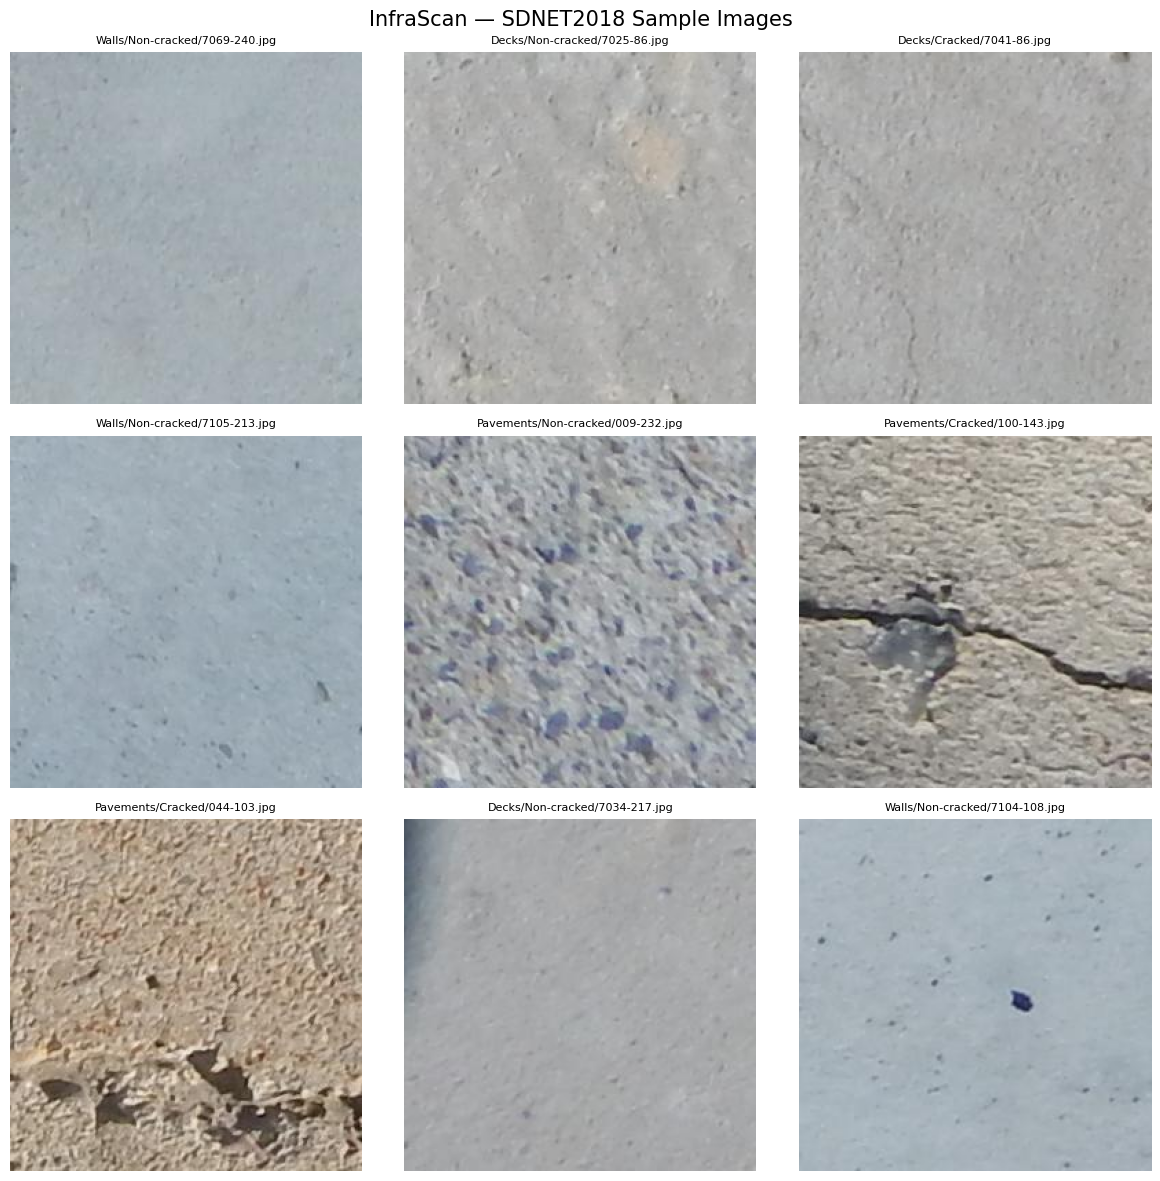

Total image files discovered: 56092
Images displayed: 9


In [12]:

# InfraScan — Step 11: Visualize sample images

import os
import random
import matplotlib.pyplot as plt
from PIL import Image

DATASET_DIR = (
    "/content/drive/MyDrive/InfraScan/"
    "datasets/raw/SDNET2018/extracted"
)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
image_paths = []

for root, dirs, files in os.walk(DATASET_DIR):
    dirs.sort()
    for filename in sorted(files):
        if os.path.splitext(filename)[1].lower() in image_extensions:
            image_paths.append(os.path.join(root, filename))

if not image_paths:
    raise FileNotFoundError(
        "No images found. Please check the Step 10 output."
    )

random.seed(42)
samples = random.sample(image_paths, min(9, len(image_paths)))

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.flatten()

for ax, path in zip(axes, samples):
    try:
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(os.path.relpath(path, DATASET_DIR), fontsize=8)
        ax.axis("off")
    except Exception as e:
        ax.set_title(f"Could not load image: {e}", fontsize=7)
        ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.suptitle("InfraScan — SDNET2018 Sample Images", fontsize=15)
plt.tight_layout()
plt.show()

print("Total image files discovered:", len(image_paths))
print("Images displayed:", len(samples))


In [13]:

# InfraScan — Step 12: Image properties analysis

import os
from collections import Counter
from PIL import Image
import pandas as pd

DATASET_DIR = (
    "/content/drive/MyDrive/InfraScan/"
    "datasets/raw/SDNET2018/extracted"
)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
records = []
failed_images = []

for root, dirs, files in os.walk(DATASET_DIR):
    dirs.sort()

    for filename in sorted(files):
        ext = os.path.splitext(filename)[1].lower()

        if ext not in image_extensions:
            continue

        path = os.path.join(root, filename)

        try:
            with Image.open(path) as img:
                records.append({
                    "filename": filename,
                    "folder": os.path.relpath(root, DATASET_DIR),
                    "width": img.width,
                    "height": img.height,
                    "format": img.format,
                    "mode": img.mode,
                    "channels": len(img.getbands()),
                    "file_size_kb": round(
                        os.path.getsize(path) / 1024, 2
                    )
                })
        except Exception as error:
            failed_images.append({
                "path": path,
                "error": str(error)
            })

df_images = pd.DataFrame(records)

if df_images.empty:
    raise ValueError(
        "No readable images found. Check the dataset directory."
    )

print("INF RASCAN — IMAGE PROPERTY REPORT".replace("INF RASCAN", "INFRASCAN"))
print("=" * 45)
print("Readable images:", len(df_images))
print("Unreadable images:", len(failed_images))

print("\nImage dimensions (width x height):")
print(
    (df_images["width"].astype(str) + " x " +
     df_images["height"].astype(str)).value_counts().head(10)
)

print("\nImage formats:")
print(df_images["format"].value_counts())

print("\nColor modes:")
print(df_images["mode"].value_counts())

print("\nChannel counts:")
print(df_images["channels"].value_counts())

print("\nImage file size (KB):")
print(df_images["file_size_kb"].describe().round(2))

print("\nSample records:")
display(df_images.head(10))

# Save the report to Google Drive
OUTPUT_DIR = (
    "/content/drive/MyDrive/InfraScan/outputs/eda"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

report_path = os.path.join(
    OUTPUT_DIR, "sdnet2018_image_properties.csv"
)
df_images.to_csv(report_path, index=False)

print("\nReport saved to:", report_path)


INFRASCAN — IMAGE PROPERTY REPORT
Readable images: 56092
Unreadable images: 0

Image dimensions (width x height):
256 x 256    56092
Name: count, dtype: int64

Image formats:
format
JPEG    56092
Name: count, dtype: int64

Color modes:
mode
RGB    56092
Name: count, dtype: int64

Channel counts:
channels
3    56092
Name: count, dtype: int64

Image file size (KB):
count    56092.00
mean         9.24
std          3.82
min          1.78
25%          6.20
50%          8.08
75%         12.18
max         21.91
Name: file_size_kb, dtype: float64

Sample records:


,filename,folder,width,height,format,mode,channels,file_size_kb
0,7001-115.jpg,Decks/Cracked,256,256,JPEG,RGB,3,9.53
1,7001-139.jpg,Decks/Cracked,256,256,JPEG,RGB,3,7.20
2,7001-151.jpg,Decks/Cracked,256,256,JPEG,RGB,3,8.13
3,7001-157.jpg,Decks/Cracked,256,256,JPEG,RGB,3,7.24
4,7001-169.jpg,Decks/Cracked,256,256,JPEG,RGB,3,7.42
5,7001-17.jpg,Decks/Cracked,256,256,JPEG,RGB,3,6.84
6,7001-173.jpg,Decks/Cracked,256,256,JPEG,RGB,3,7.66
7,7001-178.jpg,Decks/Cracked,256,256,JPEG,RGB,3,6.80
8,7001-187.jpg,Decks/Cracked,256,256,JPEG,RGB,3,6.63
9,7001-2.jpg,Decks/Cracked,256,256,JPEG,RGB,3,5.38



Report saved to: /content/drive/MyDrive/InfraScan/outputs/eda/sdnet2018_image_properties.csv


INFRASCAN — CLASS DISTRIBUTION
Total images: 56092
Cracked: 8,484 images (15.13%)
Unknown: 47,608 images (84.87%)


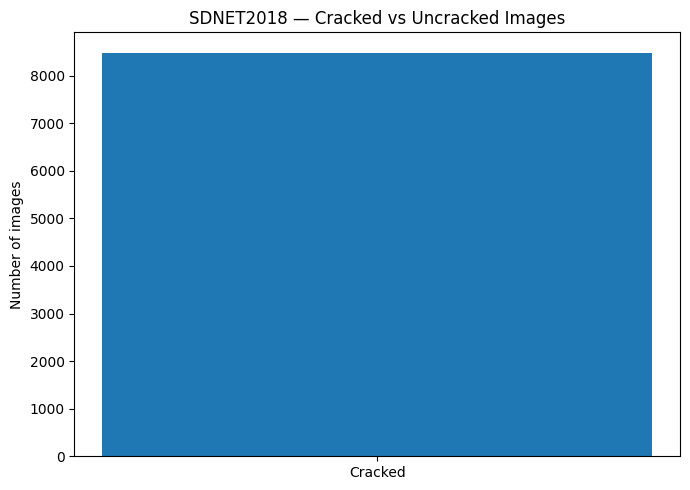


Class distribution report saved to Google Drive.


In [14]:

# InfraScan — Step 13: Class distribution analysis

import os
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

DATASET_DIR = (
    "/content/drive/MyDrive/InfraScan/"
    "datasets/raw/SDNET2018/extracted"
)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
class_counts = Counter()
image_records = []

for root, dirs, files in os.walk(DATASET_DIR):
    dirs.sort()

    for filename in files:
        if os.path.splitext(filename)[1].lower() not in image_extensions:
            continue

        path = os.path.join(root, filename)
        relative_folder = os.path.relpath(root, DATASET_DIR)
        folder_parts = relative_folder.replace("\\", "/").split("/")

        # Look for cracked/uncracked folder names in the path
        parts_lower = [part.lower() for part in folder_parts]
        if any(part in {"c", "crack", "cracked", "positive"} for part in parts_lower):
            label = "Cracked"
        elif any(part in {"u", "non-crack", "non_crack", "uncracked",
                          "un-cracked", "negative"} for part in parts_lower):
            label = "Uncracked"
        else:
            label = "Unknown"

        class_counts[label] += 1
        image_records.append({
            "path": path,
            "folder": relative_folder,
            "label": label
        })

df_classes = pd.DataFrame(image_records)

print("INF RASCAN — CLASS DISTRIBUTION".replace("INF RASCAN", "INFRASCAN"))
print("=" * 40)
print("Total images:", len(df_classes))

for label, count in class_counts.items():
    percentage = count / len(df_classes) * 100 if len(df_classes) else 0
    print(f"{label}: {count:,} images ({percentage:.2f}%)")

# Plot only when the folder labels were recognized
recognized = {
    k: v for k, v in class_counts.items()
    if k in {"Cracked", "Uncracked"}
}

if recognized:
    plt.figure(figsize=(7, 5))
    plt.bar(recognized.keys(), recognized.values())
    plt.title("SDNET2018 — Cracked vs Uncracked Images")
    plt.ylabel("Number of images")
    plt.tight_layout()
    plt.show()
else:
    print("\nClass folders were not recognized automatically.")
    print("Top-level folders:", os.listdir(DATASET_DIR))
    print("Sample folder paths:")
    print(df_classes["folder"].value_counts().head(20))

# Save records for the next EDA steps
OUTPUT_DIR = "/content/drive/MyDrive/InfraScan/outputs/eda"
os.makedirs(OUTPUT_DIR, exist_ok=True)
df_classes.to_csv(
    os.path.join(OUTPUT_DIR, "sdnet2018_class_distribution.csv"),
    index=False
)

print("\nClass distribution report saved to Google Drive.")


In [15]:

# InfraScan — Step 14: Validate image files

import os
from PIL import Image, UnidentifiedImageError
import pandas as pd

DATASET_DIR = (
    "/content/drive/MyDrive/InfraScan/"
    "datasets/raw/SDNET2018/extracted"
)

OUTPUT_DIR = "/content/drive/MyDrive/InfraScan/outputs/eda"
os.makedirs(OUTPUT_DIR, exist_ok=True)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

total_images = 0
valid_images = 0
corrupt_images = []

for root, dirs, files in os.walk(DATASET_DIR):
    dirs.sort()

    for filename in files:
        if os.path.splitext(filename)[1].lower() not in image_extensions:
            continue

        total_images += 1
        path = os.path.join(root, filename)

        try:
            # Verify file structure
            with Image.open(path) as img:
                img.verify()

            # Reopen and force decoding
            with Image.open(path) as img:
                img.load()

            valid_images += 1

        except Exception as error:
            corrupt_images.append({
                "path": path,
                "error": str(error)
            })

print("=" * 45)
print("INFRASCAN — IMAGE VALIDATION REPORT")
print("=" * 45)
print("Total images checked:", total_images)
print("Valid images:", valid_images)
print("Unreadable/corrupt images:", len(corrupt_images))

if total_images:
    print("Valid image percentage: {:.2f}%".format(
        valid_images / total_images * 100
    ))

if corrupt_images:
    corrupt_df = pd.DataFrame(corrupt_images)
    display(corrupt_df.head(20))

    report_path = os.path.join(
        OUTPUT_DIR, "sdnet2018_corrupt_images.csv"
    )
    corrupt_df.to_csv(report_path, index=False)
    print("Error report saved to:", report_path)
else:
    print("\nAll detected image files passed validation!")

print("\nStep 14 completed.")


INFRASCAN — IMAGE VALIDATION REPORT
Total images checked: 56092
Valid images: 56092
Unreadable/corrupt images: 0
Valid image percentage: 100.00%

All detected image files passed validation!

Step 14 completed.


In [16]:

# InfraScan — Step 15: Detect exact duplicate images

import os
import hashlib
from collections import defaultdict
import pandas as pd

DATASET_DIR = (
    "/content/drive/MyDrive/InfraScan/"
    "datasets/raw/SDNET2018/extracted"
)

OUTPUT_DIR = "/content/drive/MyDrive/InfraScan/outputs/eda"
os.makedirs(OUTPUT_DIR, exist_ok=True)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

hash_to_paths = defaultdict(list)
total_images = 0

def file_hash(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

for root, dirs, files in os.walk(DATASET_DIR):
    dirs.sort()

    for filename in files:
        if os.path.splitext(filename)[1].lower() not in image_extensions:
            continue

        path = os.path.join(root, filename)
        total_images += 1
        hash_to_paths[file_hash(path)].append(path)

duplicate_groups = [
    paths for paths in hash_to_paths.values() if len(paths) > 1
]

duplicate_records = []
for group_id, paths in enumerate(duplicate_groups, start=1):
    for path in paths:
        duplicate_records.append({
            "duplicate_group": group_id,
            "path": path
        })

print("=" * 45)
print("INFRASCAN — DUPLICATE IMAGE REPORT")
print("=" * 45)
print("Total images checked:", total_images)
print("Unique file contents:", len(hash_to_paths))
print("Duplicate groups:", len(duplicate_groups))
print(
    "Files belonging to duplicate groups:",
    len(duplicate_records)
)

if duplicate_records:
    duplicates_df = pd.DataFrame(duplicate_records)
    display(duplicates_df.head(20))

    report_path = os.path.join(
        OUTPUT_DIR, "sdnet2018_duplicates.csv"
    )
    duplicates_df.to_csv(report_path, index=False)
    print("Duplicate report saved to:", report_path)
else:
    print("No exact duplicate files detected.")

print("\nStep 15 completed.")


INFRASCAN — DUPLICATE IMAGE REPORT
Total images checked: 56092
Unique file contents: 56079
Duplicate groups: 13
Files belonging to duplicate groups: 26


,duplicate_group,path
0,1,/content/drive/MyDrive/InfraScan/datasets/raw/...
1,1,/content/drive/MyDrive/InfraScan/datasets/raw/...
2,2,/content/drive/MyDrive/InfraScan/datasets/raw/...
3,2,/content/drive/MyDrive/InfraScan/datasets/raw/...
4,3,/content/drive/MyDrive/InfraScan/datasets/raw/...
5,3,/content/drive/MyDrive/InfraScan/datasets/raw/...
6,4,/content/drive/MyDrive/InfraScan/datasets/raw/...
7,4,/content/drive/MyDrive/InfraScan/datasets/raw/...
8,5,/content/drive/MyDrive/InfraScan/datasets/raw/...
9,5,/content/drive/MyDrive/InfraScan/datasets/raw/...


Duplicate report saved to: /content/drive/MyDrive/InfraScan/outputs/eda/sdnet2018_duplicates.csv

Step 15 completed.


In [17]:

# InfraScan — Step 16: Consolidated EDA summary

import os
import pandas as pd
from PIL import Image
from collections import Counter

DATASET_DIR = (
    "/content/drive/MyDrive/InfraScan/"
    "datasets/raw/SDNET2018/extracted"
)
OUTPUT_DIR = "/content/drive/MyDrive/InfraScan/outputs/eda"
os.makedirs(OUTPUT_DIR, exist_ok=True)

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

records = []
corrupt_count = 0

for root, dirs, files in os.walk(DATASET_DIR):
    dirs.sort()

    for filename in sorted(files):
        if os.path.splitext(filename)[1].lower() not in extensions:
            continue

        path = os.path.join(root, filename)
        relative_folder = os.path.relpath(root, DATASET_DIR)

        try:
            with Image.open(path) as img:
                img.load()
                width, height = img.size
                image_format = img.format
                mode = img.mode

            parts = relative_folder.replace("\\", "/").split("/")
            parts_lower = [p.lower() for p in parts]

            if any(p in {"c", "crack", "cracked", "positive"}
                   for p in parts_lower):
                label = "Cracked"
            elif any(p in {"u", "non-crack", "non_crack",
                           "uncracked", "un-cracked", "negative"}
                     for p in parts_lower):
                label = "Uncracked"
            else:
                label = "Unknown"

            records.append({
                "filename": filename,
                "relative_path": os.path.relpath(path, DATASET_DIR),
                "folder": relative_folder,
                "label": label,
                "width": width,
                "height": height,
                "format": image_format,
                "mode": mode,
                "size_kb": round(os.path.getsize(path) / 1024, 2)
            })

        except Exception:
            corrupt_count += 1

df = pd.DataFrame(records)

if df.empty:
    raise ValueError(
        "No readable images found. Check the dataset path."
    )

summary = [
    ("Dataset", "SDNET2018 — Kaggle copy"),
    ("Dataset directory", DATASET_DIR),
    ("Readable images", len(df)),
    ("Unreadable image files", corrupt_count),
    ("Unknown class labels", int((df["label"] == "Unknown").sum())),
    ("Unique dimensions", str(sorted(
        (int(w), int(h))
        for w, h in df[["width", "height"]]
        .drop_duplicates().itertuples(index=False, name=None)
    ))),
    ("Image formats", str(df["format"].value_counts().to_dict())),
    ("Image modes", str(df["mode"].value_counts().to_dict())),
    ("Class counts", str(df["label"].value_counts().to_dict())),
    ("Mean file size (KB)", round(df["size_kb"].mean(), 2)),
    ("Median file size (KB)", round(df["size_kb"].median(), 2)),
]

summary_df = pd.DataFrame(summary, columns=["Metric", "Result"])

summary_path = os.path.join(OUTPUT_DIR, "sdnet2018_eda_summary.csv")
images_path = os.path.join(OUTPUT_DIR, "sdnet2018_verified_image_inventory.csv")

summary_df.to_csv(summary_path, index=False)
df.to_csv(images_path, index=False)

print("=" * 55)
print("INFRASCAN — SDNET2018 EDA SUMMARY")
print("=" * 55)
display(summary_df)

print("\nSaved summary:", summary_path)
print("Saved image inventory:", images_path)
print("\nStep 16 completed successfully!")


INFRASCAN — SDNET2018 EDA SUMMARY


,Metric,Result
0,Dataset,SDNET2018 — Kaggle copy
1,Dataset directory,/content/drive/MyDrive/InfraScan/datasets/raw/...
2,Readable images,56092
3,Unreadable image files,0
4,Unknown class labels,47608
5,Unique dimensions,"[(256, 256)]"
6,Image formats,{'JPEG': 56092}
7,Image modes,{'RGB': 56092}
8,Class counts,"{'Unknown': 47608, 'Cracked': 8484}"
9,Mean file size (KB),9.24



Saved summary: /content/drive/MyDrive/InfraScan/outputs/eda/sdnet2018_eda_summary.csv
Saved image inventory: /content/drive/MyDrive/InfraScan/outputs/eda/sdnet2018_verified_image_inventory.csv

Step 16 completed successfully!


Class counts:
label
Unknown    47608
Cracked     8484
Name: count, dtype: int64


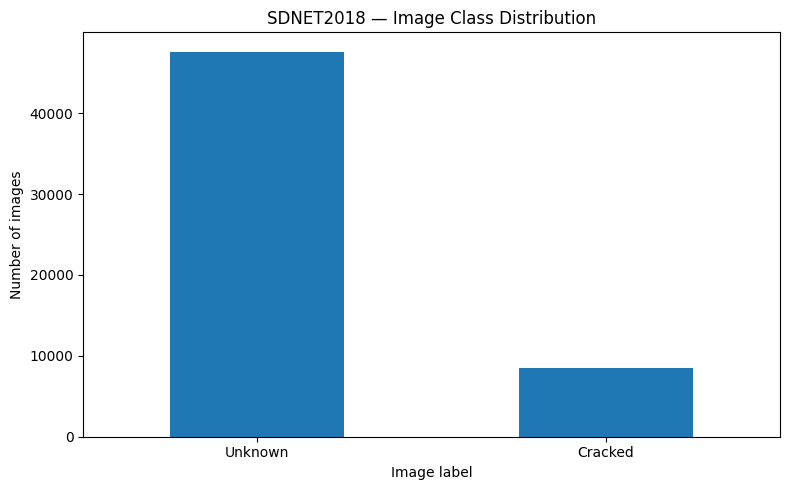


Chart saved to: /content/drive/MyDrive/InfraScan/outputs/eda/sdnet2018_class_distribution.png
Step 17 completed successfully!


In [18]:

# InfraScan — Step 17: Plot class distribution

import os
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = "/content/drive/MyDrive/InfraScan/outputs/eda"
INVENTORY_PATH = os.path.join(
    OUTPUT_DIR, "sdnet2018_verified_image_inventory.csv"
)

if not os.path.exists(INVENTORY_PATH):
    raise FileNotFoundError(
        "Run Step 16 first to create the verified image inventory."
    )

df = pd.read_csv(INVENTORY_PATH)
class_counts = df["label"].value_counts()

print("Class counts:")
print(class_counts)

plt.figure(figsize=(8, 5))
class_counts.plot(kind="bar")
plt.title("SDNET2018 — Image Class Distribution")
plt.xlabel("Image label")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.tight_layout()

CHART_PATH = os.path.join(
    OUTPUT_DIR, "sdnet2018_class_distribution.png"
)
plt.savefig(CHART_PATH, dpi=200, bbox_inches="tight")
plt.show()

print("\nChart saved to:", CHART_PATH)
print("Step 17 completed successfully!")


Image counts by infrastructure type:
infrastructure_type
Pavement         24334
Concrete wall    18138
Bridge deck      13620
Name: count, dtype: int64


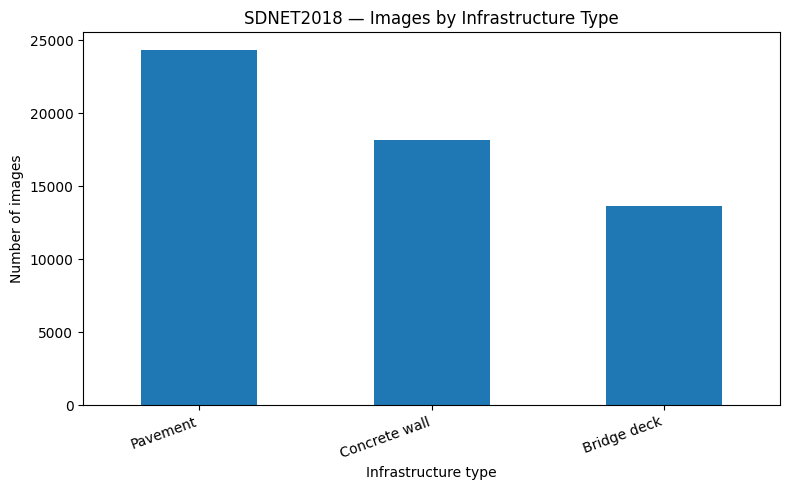


Chart saved to: /content/drive/MyDrive/InfraScan/outputs/eda/sdnet2018_infrastructure_distribution.png
CSV saved to: /content/drive/MyDrive/InfraScan/outputs/eda/sdnet2018_infrastructure_distribution.csv
Step 18 completed successfully!


In [19]:

# InfraScan — Step 18: Analyze infrastructure types

import os
import pandas as pd
import matplotlib.pyplot as plt

DATASET_DIR = (
    "/content/drive/MyDrive/InfraScan/"
    "datasets/raw/SDNET2018/extracted"
)
OUTPUT_DIR = "/content/drive/MyDrive/InfraScan/outputs/eda"

# SDNET2018 commonly uses D=deck, W=wall, P=pavement.
# We inspect folder names rather than assuming every copy is identical.

records = []
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

for root, dirs, files in os.walk(DATASET_DIR):
    dirs.sort()

    for filename in files:
        if os.path.splitext(filename)[1].lower() not in image_extensions:
            continue

        relative = os.path.relpath(root, DATASET_DIR)
        parts = relative.replace("\\", "/").split("/")
        parts_lower = [part.lower() for part in parts]

        if any(p in {"d", "deck", "decks"} for p in parts_lower):
            infrastructure = "Bridge deck"
        elif any(p in {"w", "wall", "walls"} for p in parts_lower):
            infrastructure = "Concrete wall"
        elif any(p in {"p", "pavement", "pavements"} for p in parts_lower):
            infrastructure = "Pavement"
        else:
            infrastructure = "Unknown / other"

        records.append({
            "relative_path": os.path.join(relative, filename),
            "infrastructure_type": infrastructure
        })

df_types = pd.DataFrame(records)

if df_types.empty:
    raise ValueError("No image files found. Check the dataset folder.")

counts = df_types["infrastructure_type"].value_counts()

print("Image counts by infrastructure type:")
print(counts)

plt.figure(figsize=(8, 5))
counts.plot(kind="bar")
plt.title("SDNET2018 — Images by Infrastructure Type")
plt.xlabel("Infrastructure type")
plt.ylabel("Number of images")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

chart_path = os.path.join(
    OUTPUT_DIR, "sdnet2018_infrastructure_distribution.png"
)
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

csv_path = os.path.join(
    OUTPUT_DIR, "sdnet2018_infrastructure_distribution.csv"
)
df_types.to_csv(csv_path, index=False)

print("\nChart saved to:", chart_path)
print("CSV saved to:", csv_path)
print("Step 18 completed successfully!")


In [20]:

# InfraScan — Step 19: Dataset selection inventory

import os
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/InfraScan/outputs/eda"
os.makedirs(OUTPUT_DIR, exist_ok=True)

datasets = [
    {
        "dataset_name": "SDNET2018",
        "source": "https://www.kaggle.com/datasets/aniruddhsharma/structural-defects-network-concrete-crack-images",
        "infrastructure": "Concrete bridge decks, walls, pavements",
        "primary_task": "Binary crack classification",
        "annotations": "Image-level cracked/uncracked labels",
        "milestone": "Milestone 1–2",
        "status": "Downloaded; verify local contents",
        "limitation": "Not a pixel-level segmentation dataset"
    },
    {
        "dataset_name": "Crack500",
        "source": "https://github.com/fyangneil/pavement-crack-detection",
        "infrastructure": "Road pavement",
        "primary_task": "Crack segmentation",
        "annotations": "Images and crack masks; verify downloaded version",
        "milestone": "Milestone 2",
        "status": "Selected; not yet downloaded",
        "limitation": "Road-focused; verify annotation format and license"
    },
    {
        "dataset_name": "RDD2022",
        "source": "https://github.com/sekilab/RoadDamageDetector",
        "infrastructure": "Roads",
        "primary_task": "Multi-class road damage detection",
        "annotations": "Bounding-box annotations",
        "milestone": "Milestone 2–3",
        "status": "Selected; not yet downloaded",
        "limitation": "Road-specific categories; not general building damage"
    }
]

df = pd.DataFrame(datasets)

print("INFRASCAN — DATASET SELECTION PLAN")
display(df)

output_path = os.path.join(
    OUTPUT_DIR, "infrascan_dataset_selection_plan.csv"
)
df.to_csv(output_path, index=False)

print("\nSelection plan saved to:", output_path)
print("Step 19 completed successfully!")


INFRASCAN — DATASET SELECTION PLAN


,dataset_name,source,infrastructure,primary_task,annotations,milestone,status,limitation
0,SDNET2018,https://www.kaggle.com/datasets/aniruddhsharma...,"Concrete bridge decks, walls, pavements",Binary crack classification,Image-level cracked/uncracked labels,Milestone 1–2,Downloaded; verify local contents,Not a pixel-level segmentation dataset
1,Crack500,https://github.com/fyangneil/pavement-crack-de...,Road pavement,Crack segmentation,Images and crack masks; verify downloaded version,Milestone 2,Selected; not yet downloaded,Road-focused; verify annotation format and lic...
2,RDD2022,https://github.com/sekilab/RoadDamageDetector,Roads,Multi-class road damage detection,Bounding-box annotations,Milestone 2–3,Selected; not yet downloaded,Road-specific categories; not general building...



Selection plan saved to: /content/drive/MyDrive/InfraScan/outputs/eda/infrascan_dataset_selection_plan.csv
Step 19 completed successfully!
